# Import packages

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/joacorapela/lds_itba_2026/blob/main/code/notebooks/solutions/plotOnlineKinematicsInferenceFromVideo.ipynb)

In [1]:
import numpy as np
import scipy.stats
import cv2
from google.colab.patches import cv2_imshow
from IPython.display import clear_output

# Define util functions

In [2]:
def getLDSmatricesForKinematics(dt, sigma_a, pos_x_R_std, pos_y_R_std):
    # Taken from the book
    # barShalomEtAl01-estimationWithApplicationToTrackingAndNavigation.pdf
    # section 6.3.3

    # Eq. 6.3.3-2
    B = np.array([[1, dt, .5*dt**2, 0, 0, 0],
                  [0, 1, dt, 0, 0, 0],
                  [0, 0, 1, 0, 0, 0],
                  [0, 0, 0, 1, dt, .5*dt**2],
                  [0, 0, 0, 0, 1, dt],
                  [0, 0, 0, 0, 0, 1]],
                  dtype=np.double)
    Z = np.array([[1, 0, 0, 0, 0, 0],
                  [0, 0, 0, 1, 0, 0]],
                  dtype=np.double)
    # Eq. 6.3.3-4
    Qt = np.array([[dt**4/4, dt**3/2, dt**2/2],
                      [dt**3/2, dt**2,   dt],
                      [dt**2/2, dt,      1]],
                      dtype=np.double)
    Qe = np.zeros(shape=(6, 6), dtype=np.double)
    Qe[:3, :3] = Qt
    Qe[3:6, 3:6] = Qt
    Q = sigma_a**2 * Qe
    R = np.diag(np.array([pos_x_R_std**2, pos_y_R_std**2]))

    return B, Q, Qe, Z, R


def get_background(cap, frame_indices):
    num_frames = len(frame_indices)
    frames = None
    for i, idx in enumerate(frame_indices):
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()

        if i == 0:
            frames = np.empty((frame.shape[0], frame.shape[1], frame.shape[2],
                               num_frames), dtype=np.int8)
        frames[:, :, :, i] = frame
        # breakpoint()
    median_frame = np.median(frames, axis=-1).astype(np.uint8)
    background = cv2.cvtColor(median_frame, cv2.COLOR_BGR2GRAY)
    return background


def get_moving_object_centroid(frame, background, pixel_thr_value,
                               pixel_max_value, max_contour_area):
    frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    frame_diff = cv2.absdiff(frame_gray, background)
    ret, frame_thr = cv2.threshold(frame_diff, pixel_thr_value,
                                   pixel_max_value, cv2.THRESH_BINARY)
    contours, hiearchy = cv2.findContours(frame_thr,
                                          cv2.RETR_EXTERNAL,
                                          cv2.CHAIN_APPROX_SIMPLE)
    cx, cy = np.nan, np.nan
    if len(contours) > 0:
        contour_areas = np.empty(len(contours), dtype=np.int32)
        for i, contour in enumerate(contours):
            contour_areas[i] = cv2.contourArea(contour)
        max_contour_area_index = np.argmax(contour_areas)
        if contour_areas[max_contour_area_index] < max_contour_area:
            M = cv2.moments(contours[max_contour_area_index])
            if M['m00'] != 0:
                cx = int(M['m10']/M['m00'])
                cy = int(M['m01']/M['m00'])
    return cx, cy

def update_frame(frame, cx, cy, f_mean, f_cov, ellipse_quantile,
                 centroid_color, ellipse_start_angle, ellipse_end_angle,
                 filtered_mean_color, filtered_ellipse_color,
                 ellipse_thickness, video_zoom_out_factor):
    quantile_value = scipy.stats.chi2.ppf(q=ellipse_quantile, df=2)
    eig_val, eig_vec = np.linalg.eig(f_cov)
    if eig_val[0] < eig_val[1]:
        tmp = eig_val[0]
        eig_val[0] = eig_val[1]
        eig_val[1] = tmp
        tmp = eig_vec[:, 0]
        eig_vec[:, 0] = eig_vec[:, 1]
        eig_vec[:, 1] = tmp
    major_axis_len = 2 * np.sqrt(quantile_value * eig_val[0])
    minor_axis_len = 2 * np.sqrt(quantile_value * eig_val[1])
    ellipse_axes_len = (int(major_axis_len/video_zoom_out_factor),
                        int(minor_axis_len/video_zoom_out_factor))
    ellipse_angle = np.arctan(eig_vec[1, 0]/eig_vec[0, 0]) * 180 / np.pi
    if not np.isnan(cx) and not np.isnan(cy):
        frame = cv2.circle(frame, (cx, cy), radius=0, color=centroid_color,
                           thickness=3)
    frame = cv2.circle(frame, f_mean, radius=0,
                       color=filtered_mean_color, thickness=3)
    frame = cv2.ellipse(frame, f_mean, ellipse_axes_len,
                        ellipse_angle, ellipse_start_angle,
                        ellipse_end_angle, filtered_ellipse_color,
                        ellipse_thickness)
    return frame

# Define class OnlineKalmanFilter

In [3]:
class OnlineKalmanFilter:
    """
    Class implementing the online Kalman filter algorithm for the following
    linear dynamical system:

    .. math::
       x_n &= B\\ x_{n-1} + w_n,\\ \\textrm{where}\\ w_n\\sim\\mathcal{N}(w_n|0, Q)\\, \\textrm{and}\\ x_n\\in\\Re^M

       y_n &= Z\\ x_{n-1} + v_n,\\ \\textrm{where}\\ v_n\\sim\\mathcal{N}(v_n|0, R)\\, \\textrm{and}\\ y_n\\in\\Re^N

       x_0&\\in\\mathcal{N}(x_0|m_0, V_0)

    Example use:

    .. code-block:: python

        online_kf = OnlineKalmanFilter(B, Q, m0, V0, Z, R)
        x_pred, P_pred = online_kf.predict()

        for y in ys:
            x_filt, P_filt = online_kf.update(y)
            x_pred, P_pred = online_kf.predict()

    A script using `OnlineKalmanFilter` for tracking the position of a mouse
    can be found `here
    <https://github.com/joacorapela/lds_python/blob/master/code/scripts/doOnlineFilterFWGMouseTrajectory.py>`_

    Note 1:
        invocation so `predict()` and `update(y)` should alternate. That is,
        each invocation to `update(y)` should be preceded by an invocation to
        `predict()`, and each invocation to `predict()` (except the first one)
        should be preceded by an invoation to `update(y)`.

    Note 2:
        observations :math:`y_n` should be sampled uniformly.
    """
    def __init__(self, B, Q, m0, V0, Z, R):
        self._B = B
        self._Q = Q
        self._m0 = m0
        self._V0 = V0
        self._Z = Z
        self._R = R

        self._x = m0
        self._P = V0

        M = len(m0)
        self.I = np.eye(M)

    def predict(self):
        """Predicts the next state.

        :return: (state, covariance): tuple containing the predicted state vector and covariance matrix.

        """
        self.x = self.B @ self.x
        self.P = self.B @ self.P @ self.B.T + self.Q
        return self.x, self.P

    def update(self, y):
        """Updates the current state and covariance.

        :param y: observation :math:`\\in\\Re^M`
        :return: (state, covariance): tuple containing the updated state vector and covariance matrix.

        """
        if y.ndim == 1:
            y = np.expand_dims(y, axis=1)
        if not np.isnan(y).any():
            pred_obs = self.Z @ self.x
            residual = y - pred_obs
            Stmp = self.Z @ self.P @ self.Z.T + self.R
            S = (Stmp + Stmp.T) / 2
            Sinv = np.linalg.inv(S)
            K = self.P @ self.Z.T @ Sinv
            self.x = self.x + K @ residual
            self.P = (self.I - K @ self.Z) @ self.P
        return self.x, self.P

    @property
    def B(self):
        return self._B

    @B.setter
    def B(self, B):
        self._B = B

    @property
    def Q(self):
        return self._Q

    @Q.setter
    def Q(self, Q):
        self._Q = Q

    @property
    def m0(self):
        return self._m0

    @m0.setter
    def m0(self, m0):
        self._m0 = m0

    @property
    def V0(self):
        return self._V0

    @V0.setter
    def V0(self, V0):
        self._V0 = V0

    @property
    def Z(self):
        return self._Z

    @Z.setter
    def Z(self, Z):
        self._Z = Z

    @property
    def R(self):
        return self._R

    @R.setter
    def R(self, R):
        self._R = R

    @property
    def x(self):
        return self._x

    @x.setter
    def x(self, x):
        self._x = x

    @property
    def P(self):
        return self._P

    @P.setter
    def P(self, P):
        self._P = P

# Define variables

In [4]:
# video processing variables
start_time = 0.0  # start time (secs)
frames_for_background = [1, 420, 600]  # frames to use for background extraction
video_zoom_out_factor = 2.0  #video zoom out factor
video_url = "http://www.gatsby.ucl.ac.uk/~rapela/itba2026/data/FrameTop_2021-06-03T17-00-00_ss_00-02-40_to_00-04-10.avi" # video url
pixel_thr_value = 50  # threshold value for pixels
pixel_max_value = 255  #maximum value of pixels
max_contour_area = 2000  # maximum contour area


# kinematics inference variables
sigma_a = 350.0  # acceleration standard deviation
pos_x_R_std = 0.25  # x measurement standard deviation
pos_y_R_std = 0.25  # y measurement standard deviation
m0_x = 100.0  # x coordinate of position initial condition
m0_y = 100.0  # y coordinate of position initial condition
sqrt_diag_V0_value = 100.0  # standard deviation of initial state component

# plotting variables
ellipse_thickness = 1  # thickness of the 95% confidence ellipse
ellipse_quantile = .95  # quantile of the confidence ellipse
ellipse_start_angle = 0  # start angle of the 95% confidence ellipse
ellipse_end_angle = 360  # end angle of the 95% confidence ellipse
centroid_color = (0, 0, 255)  # centroid_color
filtered_color = (0, 255, 0)  # filtered color
max_speed = 548  # maximum speed to consider for plotting (pixels / sec)

# Read video

In [5]:

cap = cv2.VideoCapture(video_url)
frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
if not cap.isOpened():
    raise RuntimeError(f"Error: {video_filename} could not be opened")
(major_ver, minor_ver, subminor_ver) = (cv2.__version__).split('.')
if int(major_ver) < 3:
    fps = cap.get(cv2.cv.CV_CAP_PROP_FPS)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)

# Build Online Kalman Filter object

In [6]:
dt = 1.0 / fps
B, Q, Qe, Z, R = getLDSmatricesForKinematics(
    dt=dt, sigma_a=sigma_a,
    pos_x_R_std=pos_x_R_std, pos_y_R_std=pos_y_R_std)
m0 = np.array([[m0_x, 0, 0, m0_y, 0, 0]], dtype=np.double).T
V0 = np.diag(np.ones(len(m0))*sqrt_diag_V0_value**2)
onlineKF = OnlineKalmanFilter(B=B, Q=Q, m0=m0, V0=V0, Z=Z, R=R)

# Infer kinematics

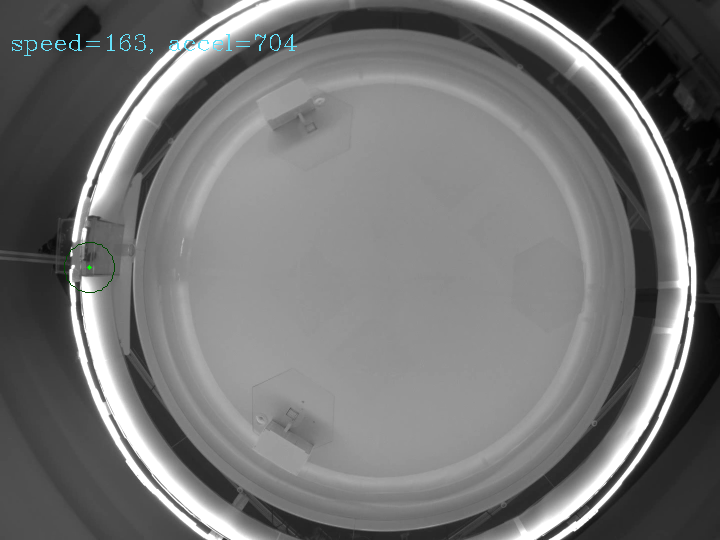

In [7]:
# dirty hack to compute the background by taking the median of three
# frames where the mouse is on different positions
background = get_background(
    cap=cap,
    frame_indices=frames_for_background)
background = cv2.resize(background, (int(frame_width/video_zoom_out_factor),
                                     int(frame_height/video_zoom_out_factor)))

# seek start frame
start_frame = start_time * fps
cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame-1)

while cap.isOpened():
    # get new video frame
    ret, frame = cap.read()
    if ret:
        frame = cv2.resize(frame,
                           (int(frame_width/video_zoom_out_factor),
                            int(frame_height/video_zoom_out_factor)))
        # get mouse centroid (cx, cy)
        cx, cy = get_moving_object_centroid(
            frame=frame, background=background,
            pixel_thr_value=pixel_thr_value,
            pixel_max_value=pixel_max_value,
            max_contour_area=max_contour_area)
    else:
        break

    # estimate the filtered state
    _, _ = onlineKF.predict()
    f_mean, f_cov = onlineKF.update(y=np.array([cx, cy]))
    speed = np.sqrt(f_mean[1]**2 + f_mean[4]**2)[0]
    acceleration = np.sqrt(f_mean[2]**2 + f_mean[5]**2)[0]

    # update frame with centroid and filter confidence ellipse
    f_mean_pos = np.array([f_mean[0], f_mean[3]])
    f_mean_pos_int = f_mean_pos.flatten().astype(int)
    f_cov_pos = np.array([[f_cov[0, 0], f_cov[0, 3]],
                          [f_cov[3, 0], f_cov[3, 3]]], dtype=np.double)
    filtered_ellipse_color = tuple([int(filtered_color[i]*speed/max_speed)
                                    for i in range(len(filtered_color))])
    frame = update_frame(frame=frame, cx=cx, cy=cy, f_mean=f_mean_pos_int,
                         f_cov=f_cov_pos,
                         ellipse_quantile=ellipse_quantile,
                         centroid_color=centroid_color,
                         ellipse_start_angle=ellipse_start_angle,
                         ellipse_end_angle=ellipse_end_angle,
                         filtered_mean_color=filtered_color,
                         filtered_ellipse_color=filtered_ellipse_color,
                         ellipse_thickness=ellipse_thickness,
                         video_zoom_out_factor=video_zoom_out_factor)
    # draw annotations
    annotation_color = (250, 225, 100)
    annotation_loc = (10, 50)
    annotation_font_scale = 0.75
    annotation = f"speed={speed:3.0f}, accel={acceleration:3.0f}"
    cv2.putText(frame, annotation, annotation_loc,
                fontFace=cv2.FONT_HERSHEY_COMPLEX,
                fontScale=annotation_font_scale, color=annotation_color)
    #
    clear_output(wait=True)
    cv2_imshow(frame)
    if cv2.waitKey(25) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()